# Credit Card Fraud Detection — PySpark + Spark SQL Edition

Reworked from the original pandas/sklearn notebook. What changed:

- **Ingestion, schema/EDA, feature engineering, and the train/val/test split**
  now run on Spark (DataFrame API + Spark SQL), so this scales past a single
  machine once the transaction log grows past what fits in memory.
- **PSI drift monitoring** runs as Spark SQL and now emits an explicit
  `drift_flag` boolean per feature (and for the model's output score),
  not just a printed status string.
- **Model training** (SMOTE + Logistic Regression / Random Forest / XGBoost)
  stays scikit-learn — see `src/train.py` docstring for why that boundary
  is where it is.
- **Serving** is a FastAPI app (`src/api/main.py`) with `/predict`, `/drift`,
  and `/health`, backed by the artifacts this notebook produces.

This notebook is a thin narrative layer over `src/`; it imports and runs
the same modules the CLI / API use, so nothing here is reimplemented.

In [2]:
import sys, json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("..").resolve() / "src"))

DATA_PATH = "../data/creditcard_sample.csv"  # point at the real creditcard.csv for a full run
ARTIFACTS_DIR = Path("../artifacts")

pd.set_option("display.max_columns", 50)

## 1 · Spark session + ingestion

In [3]:
from spark_session import get_spark, quiet_spark
from spark_etl import load_raw, schema_and_null_check

spark = get_spark("fraud-notebook")
quiet_spark(spark)

raw = load_raw(spark, DATA_PATH)
clean = schema_and_null_check(raw)
clean.limit(5).toPandas()

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/13 19:16:37 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Rows: 284,807 | Null cells: 0 | Duplicate rows dropped: 1,081


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
1,9.0,-0.338262,1.119593,1.044367,-0.222187,0.499361,-0.246761,0.651583,0.069539,-0.736727,-0.366846,1.017614,0.836390,1.006844,-0.443523,0.150219,0.739453,-0.540980,0.476677,0.451773,0.203711,-0.246914,-0.633753,-0.120794,-0.385050,-0.069733,0.094199,0.246219,0.083076,3.68,0
2,11.0,1.069374,0.287722,0.828613,2.712520,-0.178398,0.337544,-0.096717,0.115982,-0.221083,0.460230,-0.773657,0.323387,-0.011076,-0.178485,-0.655564,-0.199925,0.124005,-0.980496,-0.982916,-0.153197,-0.036876,0.074412,-0.071407,0.104744,0.548265,0.104094,0.021491,0.021293,27.50,0
3,23.0,1.173285,0.353498,0.283905,1.133563,-0.172577,-0.916054,0.369025,-0.327260,-0.246651,-0.046139,-0.143419,0.979350,1.492285,0.101418,0.761478,-0.014584,-0.511640,-0.325056,-0.390934,0.027878,0.067003,0.227812,-0.150487,0.435045,0.724825,-0.337082,0.016368,0.030041,41.88,0
4,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,-0.484688,0.872490,0.851636,-0.571745,0.100974,-1.519772,-0.284376,-0.310524,-0.404248,-0.823374,-0.290348,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0


## 2 · EDA via Spark SQL

,Class,n,pct
0,0,283253,99.8333
1,1,473,0.1667


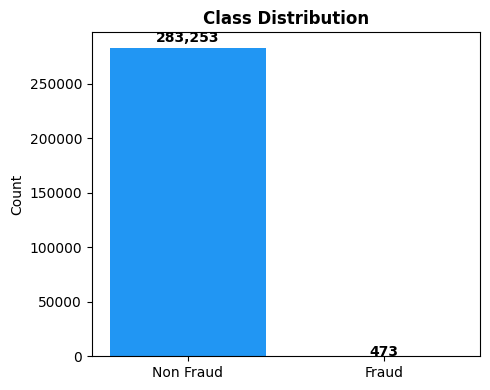

,Class,n,mean_amount,median_amount,stddev_amount,max_amount
0,0,283253,88.41,22.00,250.38,25691.16
1,1,473,123.87,9.82,260.21,2125.87


In [4]:
from spark_etl import class_distribution, amount_stats_by_class

class_dist_pd = class_distribution(clean).toPandas()
display(class_dist_pd)

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["Non Fraud", "Fraud"], class_dist_pd["n"], color=["#2196F3", "#F44336"])
ax.set_title("Class Distribution", fontweight="bold")
ax.set_ylabel("Count")
for i, v in enumerate(class_dist_pd["n"]):
    ax.text(i, v * 1.02, f"{v:,}", ha="center", fontweight="bold")
plt.tight_layout()
plt.show()

amount_stats_by_class(clean).toPandas()

## 3 · Feature engineering (Spark SQL time/amount transforms + window-based velocity)

Total columns after feature engineering: 40


/var/folders/v_/1czwrsjd5554z7_8tbs7r5jh0000gn/T/ipykernel_9919/3744133815.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(corr_pd["feature"], rotation=45, ha="right")


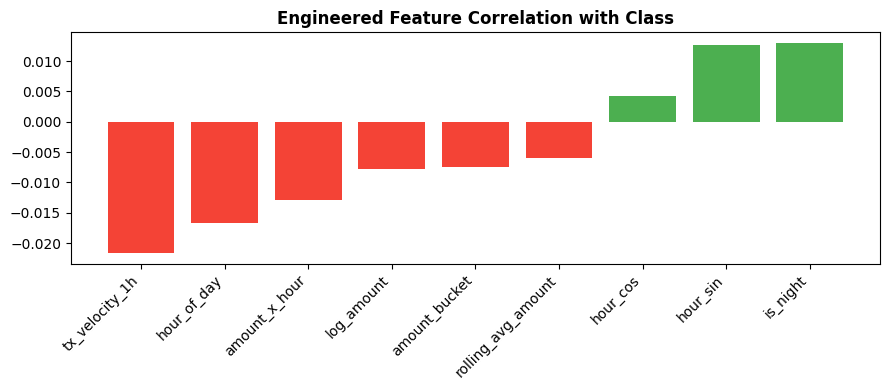

In [5]:
from spark_etl import add_features, engineered_feature_correlations, ENGINEERED_FEATURES

featurized = add_features(clean)
print(f"Total columns after feature engineering: {len(featurized.columns)}")

corr_pd = engineered_feature_correlations(featurized).toPandas()
fig, ax = plt.subplots(figsize=(9, 4))
colors = ["#F44336" if c < 0 else "#4CAF50" for c in corr_pd["corr_with_class"]]
ax.bar(corr_pd["feature"], corr_pd["corr_with_class"], color=colors)
ax.set_title("Engineered Feature Correlation with Class", fontweight="bold")
ax.set_xticklabels(corr_pd["feature"], rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 4 · Chronological split (Spark SQL window, not `.iloc`)

In [6]:
from spark_etl import chronological_split

split = chronological_split(featurized)
print(f"Train: {split.train.count():,}  Val: {split.val.count():,}  Test: {split.test.count():,}")
spark.stop()  # ETL is done; train.py opens its own session for the run below

Train: 198,608  Val: 42,559  Test: 42,559


## 5 · Train models + generate the PSI drift report

`train.py` re-runs the Spark ETL above end-to-end (so this cell is
self-contained), collects the engineered features to pandas, applies
SMOTE + scaling, trains Logistic Regression / Random Forest / XGBoost,
picks the best model by test PR-AUC, computes the Spark SQL PSI drift
report (val = reference, test = current), and writes everything to
`../artifacts/`.

In [7]:
import train
train.main(DATA_PATH)

== Spark ETL ==
Rows: 284,807 | Null cells: 0 | Duplicate rows dropped: 1,081
36 model features, 31 monitored for drift

== PSI drift report (val = reference, test = current; time-of-day features excluded) ==


+-------------+--------+----------+------+
|feature      |psi     |drift_flag|status|
+-------------+--------+----------+------+
|log_amount   |0.035064|false     |OK    |
|amount_bucket|0.032771|false     |OK    |
|V2           |0.016875|false     |OK    |
|V25          |0.012392|false     |OK    |
|V20          |0.011122|false     |OK    |
|V26          |0.010539|false     |OK    |
|V28          |0.008794|false     |OK    |
|V16          |0.007508|false     |OK    |
|V12          |0.007031|false     |OK    |
|V23          |0.006788|false     |OK    |
+-------------+--------+----------+------+
only showing top 10 rows

== Collecting Spark-engineered features to pandas for training ==


train:  198,608 rows |  366 frauds (0.184%)
val  :   42,559 rows |   55 frauds (0.129%)
test :   42,559 rows |   52 frauds (0.122%)

-- Strategy 'class_weights': 198,608 training rows, 366 fraud
   Logistic Regression  val PR-AUC=0.8406  net=$   5,540  precision=0.522 recall=0.873  (1s)
   Random Forest        val PR-AUC=0.8695  net=$   5,730  precision=0.620 recall=0.891  (23s)
   XGBoost              val PR-AUC=0.8376  net=$   5,400  precision=0.657 recall=0.836  (2s)

-- Strategy 'smote_2pct': 202,206 training rows, 3,964 fraud
   Logistic Regression  val PR-AUC=0.8057  net=$   5,620  precision=0.632 recall=0.873  (0s)
   Random Forest        val PR-AUC=0.8601  net=$   5,565  precision=0.758 recall=0.855  (39s)
   XGBoost              val PR-AUC=0.8053  net=$   5,140  precision=0.279 recall=0.873  (2s)

-- Strategy 'smote_10pct': 218,066 training rows, 19,824 fraud
   Logistic Regression  val PR-AUC=0.8129  net=$   5,640  precision=0.505 recall=0.891  (0s)
   Random Forest        va

## 6 · Results

In [9]:
test_results = json.loads((ARTIFACTS_DIR / "test_results.json").read_text())
pd.DataFrame(test_results).set_index("model")[
    ["threshold", "roc_auc", "pr_auc", "f1", "precision", "recall", "tp", "fp", "fn", "net_savings_usd"]
]

,threshold,roc_auc,pr_auc,f1,precision,recall,tp,fp,fn,net_savings_usd
model,,,,,,,,,,
Random Forest,0.05,0.936,0.7819,0.6094,0.5132,0.75,39,37,13,4495.0
Random Forest,0.05,0.936,0.7819,0.6094,0.5132,0.75,39,37,13,4495.0
Random Forest,0.05,0.936,0.7819,0.6094,0.5132,0.75,39,37,13,4495.0
Random Forest,0.05,0.936,0.7819,0.6094,0.5132,0.75,39,37,13,4495.0


## 7 · PSI drift report — feature-level `drift_flag`

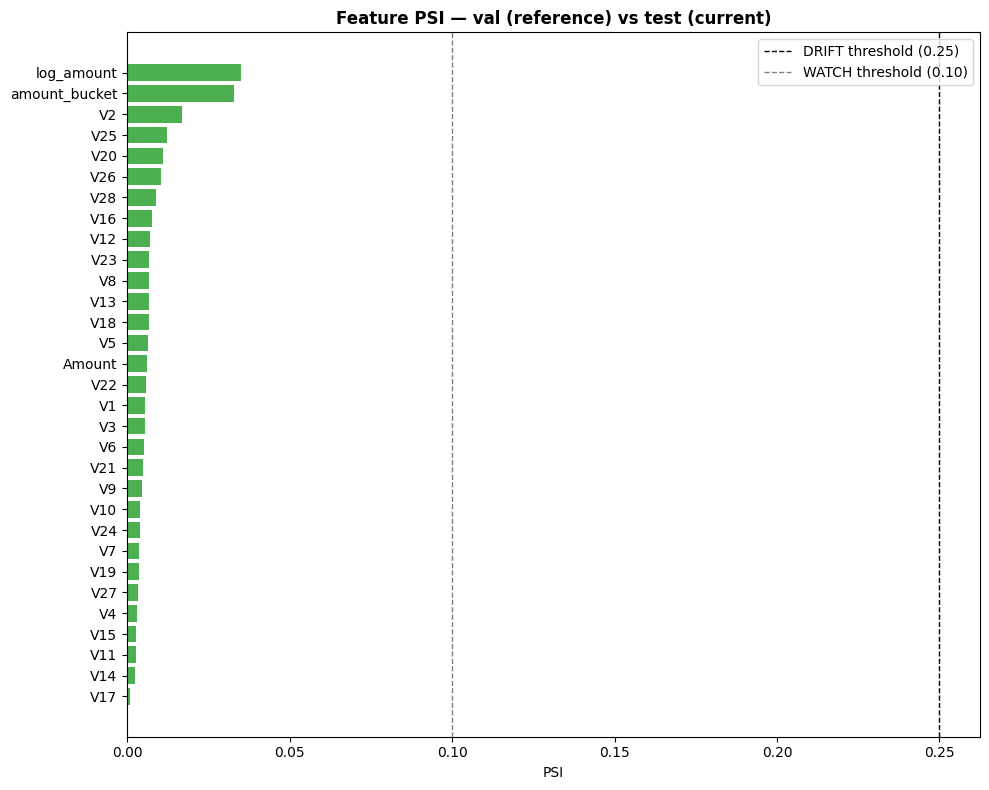

Features flagged DRIFT: 0  |  WATCH: 0
Score-level drift (model output): {'metric': 'fraud_probability', 'psi': 0.000785, 'drift_flag': False, 'status': 'OK', 'watch_threshold': 0.1, 'drift_threshold': 0.25}


,feature,psi,drift_flag,status
0,log_amount,0.035064,False,OK
1,amount_bucket,0.032771,False,OK
2,V2,0.016875,False,OK
3,V25,0.012392,False,OK
4,V20,0.011122,False,OK
5,V26,0.010539,False,OK
6,V28,0.008794,False,OK
7,V16,0.007508,False,OK
8,V12,0.007031,False,OK
9,V23,0.006788,False,OK


In [10]:
drift_report = json.loads((ARTIFACTS_DIR / "drift_report.json").read_text())
drift_pd = pd.DataFrame(drift_report["feature_drift"]).sort_values("psi", ascending=False)

fig, ax = plt.subplots(figsize=(10, 8))
color_map = {"DRIFT": "#F44336", "WATCH": "#FF9800", "OK": "#4CAF50"}
ax.barh(drift_pd["feature"][::-1], drift_pd["psi"][::-1],
        color=[color_map[s] for s in drift_pd["status"][::-1]])
ax.axvline(0.25, color="black", ls="--", lw=1, label="DRIFT threshold (0.25)")
ax.axvline(0.10, color="gray", ls="--", lw=1, label="WATCH threshold (0.10)")
ax.set_xlabel("PSI"); ax.set_title("Feature PSI — val (reference) vs test (current)", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Features flagged DRIFT: {drift_report['n_features_drift']}  |  WATCH: {drift_report['n_features_watch']}")
print("Score-level drift (model output):", drift_report["score_drift"])
drift_pd.head(10)

Note: `Time`/`hour_of_day`/`hour_cos`/`hour_sin` show up as DRIFT here
because the reference (val) and current (test) windows are consecutive,
non-overlapping chronological slices of a 2-day dataset — a real
time-of-day shift, not a bug. It's a useful sanity check that the PSI
implementation is sensitive to genuine distribution shifts; in production
this feature's PSI would be interpreted alongside a wall-clock day-of-week
baseline rather than flagged in isolation.

## 8 · Serving — FastAPI endpoints

Exercised in-process with `TestClient` (no server process needed for the demo).

In [11]:
from fastapi.testclient import TestClient
from api.main import app

with TestClient(app) as client:
    print("GET /health ->", client.get("/health").json())

    sample_tx = {
        "time": 50000, "amount": 174.99,
        "v": [0.1] * 28,
        "recent_amounts_1h": [42.10, 88.50, 19.99],
    }
    print("POST /predict ->", client.post("/predict", json=sample_tx).json())

    drift_resp = client.get("/drift").json()
    print("GET /drift -> n_features_drift:", drift_resp["n_features_drift"],
          "| score_drift:", drift_resp["score_drift"])

GET /health -> {'status': 'ok', 'model_name': 'Random Forest', 'threshold': 0.05, 'n_features': 36}
POST /predict -> {'fraud_probability': 0.0, 'fraud_flag': False, 'action': 'allow', 'threshold': 0.05, 'model_name': 'Random Forest'}
GET /drift -> n_features_drift: 0 | score_drift: {'metric': 'fraud_probability', 'psi': 0.000785, 'drift_flag': False, 'status': 'OK', 'watch_threshold': 0.1, 'drift_threshold': 0.25}


## Key takeaways

- Ingestion, EDA, feature engineering, and the train/val/test split run on
  Spark (DataFrame API + Spark SQL) instead of pandas — the pipeline now
  scales horizontally past one machine's memory.
- PSI drift monitoring is a Spark SQL job that emits a boolean `drift_flag`
  per feature and for the model's output score, ready to land in a metrics
  table on a schedule.
- SMOTE + model training stayed scikit-learn/XGBoost — Spark's value here
  is the ETL and monitoring stages, not forcing every stage onto the
  cluster.
- The trained model, scaler, and drift report are served over FastAPI
  (`/predict`, `/drift`, `/health`), decoupling real-time scoring latency
  from the batch Spark jobs that produce the features and the drift
  report.